# Spoiler Detection in IMDb Reviews Using Deep Learning

**Research question:** Can a small TextCNN detect spoiler-marked reviews for previously unseen movies/TV shows, and how do input length and class weighting affect performance?

Source: https://www.kaggle.com/datasets/rmisra/imdb-spoiler-dataset

Dataset paper: https://arxiv.org/abs/2212.06034

Labels reflect users' spoiler flags, not independently verified truth. The dataset includes movies and TV shows.

In [6]:
from pathlib import Path
import os, re, json, html, random, time, hashlib, platform, copy
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ijson, joblib, torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, precision_recall_curve, classification_report,
    ConfusionMatrixDisplay)
from IPython.display import display

DATA_DIR = Path('.')   # Change this path if using Google Drive or another folder.
OUT = Path('spoiler_outputs'); OUT.mkdir(exist_ok=True)
SEED = 42
MAX_REVIEWS = 30_000      # None = all eligible rows; 3_000 for a pipeline check only.
VOCAB_SIZE = 20_000
LENGTHS = [128, 256]     # Regex tokens, not characters; keep the first N tokens.
EPOCHS = 6
PATIENCE = 2
BATCH_SIZE = 64
LR = 1e-3
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
seed_everything(SEED)
print('Device:', DEVICE, '| Python:', platform.python_version(), '| Torch:', torch.__version__)


Device: cpu | Python: 3.14.7 | Torch: 2.14.0


## 1. Read, clean and sample
The reader handles JSON arrays and JSON Lines without loading the full 1 GB review file into memory. Reservoir sampling is uniform over eligible rows before deduplication; final group proportions can differ from the full dataset. No deliberate class balancing is applied. Invalid labels raise an error rather than silently becoming negative.

Sampling and cleaning scan the entire file once. Default preprocessing preserves negation and punctuation, normalizes HTML/whitespace and lowercases. Explicit spoiler words remain initially; a later sensitivity analysis checks dependence on them.


{'eligible_source_rows': 573913, 'skipped_rows': 0, 'sampled_rows': 30000}
Conflicting duplicate texts excluded: 1
After cleanup: (29995, 6)


,n,median_words
label,,
0,22195,170.0
1,7800,260.0


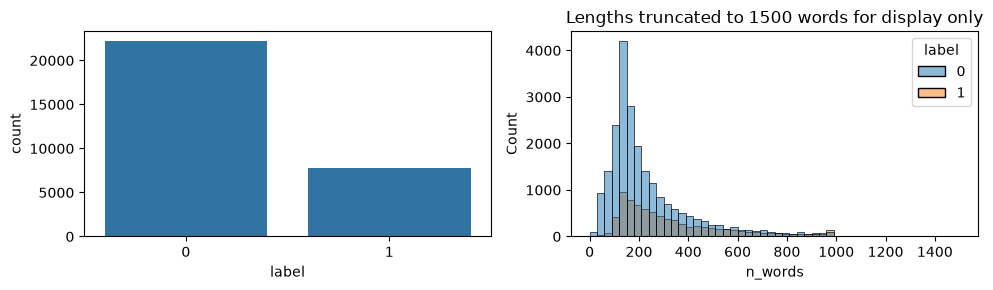

In [7]:
def records(path):
    if not path.exists():
        raise FileNotFoundError(f'Place {path.name} in {path.parent.resolve()}')
    with path.open('rb') as f:
        first = f.read(4096).lstrip()[:1]; f.seek(0)
        if first == b'[':
            yield from ijson.items(f, 'item')
        else:
            for line in f:
                if line.strip(): yield json.loads(line)

def normalize(text):
    text = html.unescape(str(text))
    text = re.sub(r'<[^>]*>', ' ', text)
    return re.sub(r'\s+', ' ', text).strip().lower()

def parse_label(value):
    if isinstance(value, bool): return int(value)
    if str(value).strip().lower() in ('1', 'true'): return 1
    if str(value).strip().lower() in ('0', 'false'): return 0
    raise ValueError(f'Unexpected is_spoiler value: {value!r}')

def load_reviews(path, cap, seed):
    rng = random.Random(seed); rows=[]; eligible=0; skipped=0
    for r in records(path):
        if not r.get('review_text') or not r.get('movie_id') or r.get('is_spoiler') is None:
            skipped += 1; continue
        text = normalize(r['review_text'])
        if not text: skipped += 1; continue
        row = {'movie_id': str(r['movie_id']), 'user_id': str(r.get('user_id', '')),
               'text': text, 'label': parse_label(r['is_spoiler'])}
        eligible += 1
        if cap is None or len(rows) < cap: rows.append(row)
        else:
            j = rng.randrange(eligible)
            if j < cap: rows[j] = row
    print({'eligible_source_rows': eligible, 'skipped_rows': skipped, 'sampled_rows': len(rows)})
    return pd.DataFrame(rows)

reviews = load_reviews(DATA_DIR/'IMDB_reviews.json', MAX_REVIEWS, SEED)
reviews['text_hash'] = reviews.text.map(lambda s: hashlib.sha256(s.encode()).hexdigest())
conflicting = reviews.groupby('text_hash').label.nunique()
conflicting = set(conflicting[conflicting > 1].index)
print('Conflicting duplicate texts excluded:', len(conflicting))
reviews = reviews[~reviews.text_hash.isin(conflicting)].drop_duplicates('text_hash').reset_index(drop=True)
reviews['n_words'] = reviews.text.str.split().str.len()
assert set(reviews.label.unique()) == {0, 1}, 'Both classes are required.'
print('After cleanup:', reviews.shape)
display(reviews.groupby('label').agg(n=('text','size'), median_words=('n_words','median')))
fig, axes = plt.subplots(1,2,figsize=(10,3))
sns.countplot(data=reviews,x='label',ax=axes[0])
sns.histplot(data=reviews,x='n_words',hue='label',bins=50,binrange=(0,1500),ax=axes[1])
axes[1].set_title('Lengths truncated to 1500 words for display only'); plt.tight_layout()


**Write after running:** How many rows were excluded? Are classes imbalanced? How much text will each input limit omit? The deduplication check covers the selected sample, not all unsampled source rows.


## 2. Movie-disjoint splits
Split about 80% of movies into development and 20% into test, then split development movies 80/20 into training and validation: approximately 64/16/20 overall by groups. Review counts need not match these fractions. This replaces the official-split design discussed for the separate Stanford sentiment dataset: this spoiler dataset needs its own split.

Do not search for a favorable random split. Report class rates and sample counts. Identical cleaned reviews are removed before splitting. The same users may appear across splits; quantify this limitation.


In [8]:
gss = GroupShuffleSplit(n_splits=1, test_size=.20, random_state=SEED)
dev_i, test_i = next(gss.split(reviews, groups=reviews.movie_id))
dev = reviews.iloc[dev_i].reset_index(drop=True)
train_i, val_i = next(gss.split(dev, groups=dev.movie_id))
train = dev.iloc[train_i].reset_index(drop=True)
val = dev.iloc[val_i].reset_index(drop=True)
test = reviews.iloc[test_i].reset_index(drop=True)
for a,b in [(train,val),(train,test),(val,test)]:
    assert not set(a.movie_id) & set(b.movie_id)
    assert not set(a.text_hash) & set(b.text_hash)
for name, frame in [('train',train),('validation',val),('test',test)]:
    assert frame.label.nunique() == 2, f'{name} needs both classes; increase sample size.'
    print(name, len(frame), 'movies:',frame.movie_id.nunique(), 'spoiler rate:',round(frame.label.mean(),3))
    frame[['text_hash','movie_id','label']].to_csv(OUT/f'{name}_manifest.csv',index=False)
print('Known user overlap train/test:', len((set(train.user_id)-{''}) & (set(test.user_id)-{''})))
# Initial manual audit: only training examples; do not expose test examples during development.
audit = pd.concat([train[train.label==y].sample(min(10,sum(train.label==y)),random_state=SEED) for y in [0,1]])
audit[['movie_id','label','text']].to_csv(OUT/'initial_training_audit.csv',index=False)


train 19175 movies: 993 spoiler rate: 0.258
validation 4828 movies: 249 spoiler rate: 0.261
test 5992 movies: 311 spoiler rate: 0.266
Known user overlap train/test: 1065


## 3. Baseline
Fit TF-IDF and logistic regression on training data only. A majority-class reference and the linear model help determine whether CNN complexity adds value. Compare models on validation first; test is evaluated once after choices are fixed.


In [9]:
def metrics(y,p,threshold=.5):
    pred = np.asarray(p) >= threshold
    return dict(accuracy=accuracy_score(y,pred), precision=precision_score(y,pred,zero_division=0),
        recall=recall_score(y,pred,zero_division=0), f1=f1_score(y,pred,zero_division=0),
        macro_f1=f1_score(y,pred,average='macro',zero_division=0),
        average_precision=average_precision_score(y,p))

def choose_threshold(y,p):
    precision, recall, thresholds = precision_recall_curve(y,p)
    f1 = 2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)
    return float(thresholds[np.argmax(f1)])

baseline = make_pipeline(TfidfVectorizer(max_features=30_000,ngram_range=(1,2),min_df=2),
    LogisticRegression(max_iter=1000,random_state=SEED))
baseline.fit(train.text, train.label)
base_val = baseline.predict_proba(val.text)[:,1]
base_threshold = choose_threshold(val.label,base_val)
print('Majority validation accuracy:', max(val.label.mean(),1-val.label.mean()))
print('TF-IDF validation:', metrics(val.label,base_val,base_threshold))
joblib.dump(baseline,OUT/'tfidf_logistic.joblib')


Majority validation accuracy: 0.7390223695111848
TF-IDF validation: {'accuracy': 0.6893123446561723, 'precision': 0.43603411513859275, 'recall': 0.6492063492063492, 'f1': 0.5216836734693877, 'macro_f1': 0.6458111618880681, 'average_precision': 0.5210554090523214}


['spoiler_outputs/tfidf_logistic.joblib']

## 4. Train-only vocabulary and TextCNN
Vocabulary is learned only from training text and reused for all experiments. Sigmoid is used at prediction time; BCEWithLogitsLoss receives raw logits. Weighted training uses training negatives/positives as `pos_weight`. Padding-only convolution windows are excluded from max pooling.

The linear baseline sees full reviews, while CNN inputs are truncated. Treat it as a practical reference, not a controlled architecture comparison.


In [10]:
TOKEN_RE = re.compile(r"\w+|[^\w\s]")
def tokenize(s): return TOKEN_RE.findall(s)
counts = Counter(t for s in train.text for t in tokenize(s))
vocab = {'<PAD>':0,'<UNK>':1}
vocab.update({t:i+2 for i,(t,_) in enumerate(counts.most_common(VOCAB_SIZE-2))})
(OUT/'vocab.json').write_text(json.dumps(vocab),encoding='utf-8')

class ReviewsDataset(Dataset):
    def __init__(self,frame,length):
        self.x=[]; self.y=frame.label.to_numpy(dtype=np.float32)
        for s in frame.text:
            ids=[vocab.get(t,1) for t in tokenize(s)[:length]]
            self.x.append(ids+[0]*(length-len(ids)))
    def __len__(self): return len(self.y)
    def __getitem__(self,i): return torch.tensor(self.x[i]),torch.tensor(self.y[i])

class TextCNN(nn.Module):
    def __init__(self,n_vocab,dropout=.4):
        super().__init__()
        self.embedding=nn.Embedding(n_vocab,100,padding_idx=0)
        self.convs=nn.ModuleList([nn.Conv1d(100,64,k) for k in (3,4,5)])
        self.dropout=nn.Dropout(dropout); self.fc=nn.Linear(64*3,1)
    def forward(self,x):
        z=self.embedding(x).transpose(1,2); pooled=[]
        for conv in self.convs:
            h=torch.relu(conv(z)); k=conv.kernel_size[0]
            valid=(x!=0).unfold(1,k,1).any(dim=-1).unsqueeze(1)
            h=h.masked_fill(~valid,torch.finfo(h.dtype).min)
            v=h.amax(dim=2)
            v=torch.where(valid.any(dim=2),v,torch.zeros_like(v))
            pooled.append(v)
        return self.fc(self.dropout(torch.cat(pooled,dim=1))).squeeze(1)

@torch.no_grad()
def predict(model,loader):
    model.eval(); probs=[]; labels=[]
    for x,y in loader:
        probs.extend(torch.sigmoid(model(x.to(DEVICE))).cpu().numpy()); labels.extend(y.numpy())
    return np.asarray(labels),np.asarray(probs)

def fit_cnn(length,weighted,seed=SEED,dropout=.4,tag=None):
    seed_everything(seed)
    name=tag or f'cnn_len{length}_weighted{weighted}'
    train_loader=DataLoader(ReviewsDataset(train,length),batch_size=BATCH_SIZE,shuffle=True)
    val_loader=DataLoader(ReviewsDataset(val,length),batch_size=BATCH_SIZE)
    model=TextCNN(len(vocab),dropout).to(DEVICE)
    weight=float((train.label==0).sum()/(train.label==1).sum()) if weighted else 1.0
    loss_fn=nn.BCEWithLogitsLoss(pos_weight=torch.tensor(weight,device=DEVICE))
    optimizer=torch.optim.Adam(model.parameters(),lr=LR)
    best=-1.; stale=0; history=[]; started=time.perf_counter()
    for epoch in range(EPOCHS):
        model.train(); total=0.
        for x,y in train_loader:
            x,y=x.to(DEVICE),y.to(DEVICE)
            optimizer.zero_grad(); loss=loss_fn(model(x),y); loss.backward(); optimizer.step()
            total += loss.item()*len(y)
        vy,vp=predict(model,val_loader); ap=average_precision_score(vy,vp)
        history.append({'epoch':epoch+1,'train_loss':total/len(train),'val_ap':ap,
                        'val_f1_at_05':f1_score(vy,vp>=.5,zero_division=0)})
        print(name,history[-1])
        if ap>best+1e-5:
            best=ap; stale=0
            torch.save(model.state_dict(),OUT/f'{name}.pt')
        else: stale+=1
        if stale>=PATIENCE: break
    model.load_state_dict(torch.load(OUT/f'{name}.pt',map_location=DEVICE,weights_only=True))
    vy,vp=predict(model,val_loader); threshold=choose_threshold(vy,vp)
    hist=pd.DataFrame(history); hist.to_csv(OUT/f'{name}_history.csv',index=False)
    result={'name':name,'length':length,'weighted':weighted,'seed':seed,'dropout':dropout,
            'threshold':threshold,'seconds':time.perf_counter()-started,**metrics(vy,vp,threshold)}
    return result, hist


## 5. Controlled experiments and validation decisions
Four conditions: 128/256 tokens × unweighted/weighted BCE. Same split, architecture, learning rate and seed. Checkpoints are chosen by validation average precision; thresholds maximize validation spoiler F1. Average precision summarizes the precision–recall curve and is reported explicitly as AP, rather than a trapezoidal PR-AUC.

Do not select settings using test results. A single seed is a limitation; after identifying promising settings, repeat them with additional seeds if resources permit.


cnn_len128_weightedFalse {'epoch': 1, 'train_loss': 0.6005834367968423, 'val_ap': 0.3536822444177645, 'val_f1_at_05': 0.0}
cnn_len128_weightedFalse {'epoch': 2, 'train_loss': 0.5559154551638462, 'val_ap': 0.4025643620644349, 'val_f1_at_05': 0.04192546583850932}
cnn_len128_weightedFalse {'epoch': 3, 'train_loss': 0.5371385609000106, 'val_ap': 0.41125620188186707, 'val_f1_at_05': 0.1049519586104952}
cnn_len128_weightedFalse {'epoch': 4, 'train_loss': 0.5130418448622255, 'val_ap': 0.4183219600360757, 'val_f1_at_05': 0.21980830670926518}
cnn_len128_weightedFalse {'epoch': 5, 'train_loss': 0.48834883010371877, 'val_ap': 0.41861962552547805, 'val_f1_at_05': 0.18231665524331733}
cnn_len128_weightedFalse {'epoch': 6, 'train_loss': 0.45551128309895195, 'val_ap': 0.4149911869702134, 'val_f1_at_05': 0.2215067611075338}
cnn_len128_weightedTrue {'epoch': 1, 'train_loss': 1.0848014370434598, 'val_ap': 0.3695497524984707, 'val_f1_at_05': 0.4418604651162791}
cnn_len128_weightedTrue {'epoch': 2, 'train

,name,length,weighted,seed,dropout,threshold,seconds,accuracy,precision,recall,f1,macro_f1,average_precision
3,cnn_len256_weightedTrue,256,True,42,0.4,0.452812,699.381413,0.642502,0.389469,0.651587,0.487530,0.606519,0.486141
2,cnn_len256_weightedFalse,256,False,42,0.4,0.183927,1124.551288,0.593206,0.360759,0.723810,0.481521,0.573412,0.479864
0,cnn_len128_weightedFalse,128,False,42,0.4,0.171202,438.003226,0.494615,0.310655,0.768254,0.442413,0.490146,0.418620
1,cnn_len128_weightedTrue,128,True,42,0.4,0.544363,397.764585,0.583471,0.340687,0.637302,0.444014,0.555506,0.414616


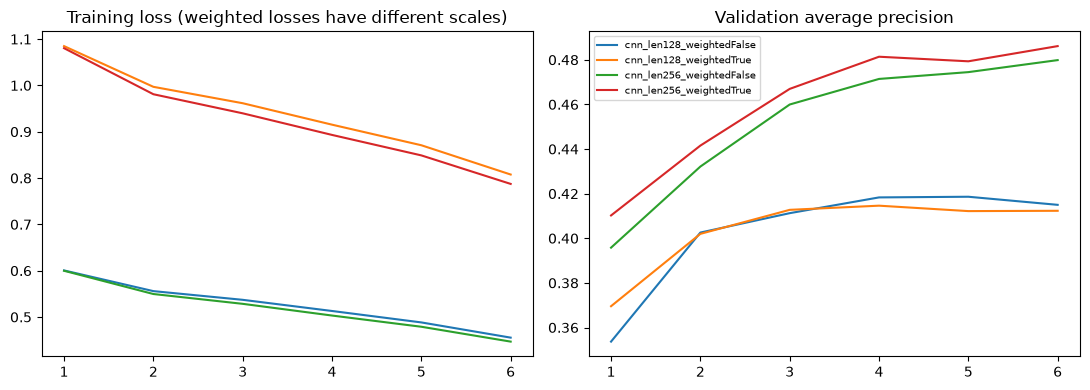

In [11]:
results=[]; histories={}
for length in LENGTHS:
    for weighted in [False,True]:
        result,hist=fit_cnn(length,weighted)
        results.append(result); histories[result['name']]=hist
validation_results=pd.DataFrame(results).sort_values('average_precision',ascending=False)
display(validation_results)
validation_results.to_csv(OUT/'validation_experiments.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for name,h in histories.items():
    axes[0].plot(h.epoch,h.train_loss,label=name)
    axes[1].plot(h.epoch,h.val_ap,label=name)
axes[0].set_title('Training loss (weighted losses have different scales)')
axes[1].set_title('Validation average precision'); axes[1].legend(fontsize=7)
plt.tight_layout()


**Your interpretation / 自己填写:** Which input length helps? Does weighting change recall and precision? Is improvement meaningful relative to added time? Do curves suggest overfitting? Weighted and unweighted training losses are not directly comparable.

Document one evidence-based follow-up experiment before running it. For example, increase dropout only if curves support an overfitting concern. A result that fails to improve is still informative. Do not invent observations.


In [12]:
# Optional evidence-based iteration. Explain the reason in the preceding markdown first.
RUN_FOLLOWUP = False
if RUN_FOLLOWUP:
    candidate=validation_results.iloc[0]
    result,hist=fit_cnn(int(candidate['length']),bool(candidate['weighted']),
                        dropout=.6,tag='cnn_followup_dropout06')
    results.append(result); histories[result['name']]=hist
    validation_results=pd.DataFrame(results).sort_values('average_precision',ascending=False)
    validation_results.to_csv(OUT/'validation_experiments.csv',index=False)
    display(validation_results)


## 6. Validation error audit and shortcut sensitivity
Review up to 10 false positives and 10 false negatives, plus a few correct cases. Disagreement with a user flag does not establish a genuine model error. Record whether movie knowledge would be required. Removing explicit spoiler words at inference is a sensitivity check, not a fair retrained-model comparison or proof of causal reliance.


In [13]:
chosen=validation_results.iloc[0].to_dict()
best_model=TextCNN(len(vocab),float(chosen['dropout'])).to(DEVICE)
best_model.load_state_dict(torch.load(OUT/f"{chosen['name']}.pt",map_location=DEVICE,weights_only=True))
length=int(chosen['length']); threshold=float(chosen['threshold'])
_,vp=predict(best_model,DataLoader(ReviewsDataset(val,length),batch_size=BATCH_SIZE))
val_audit=val.copy(); val_audit['score']=vp; val_audit['prediction']=(vp>=threshold).astype(int)
parts=[]
for y,p in [(0,1),(1,0),(0,0),(1,1)]:
    f=val_audit[(val_audit.label==y)&(val_audit.prediction==p)]
    n=10 if y!=p else 3
    parts.append(f.sample(min(n,len(f)),random_state=SEED))
audit=pd.concat(parts)
audit['human_notes']=''; audit['label_uncertain']=''
audit.to_csv(OUT/'validation_error_audit.csv',index=False)
print('Read exported audit locally; no need to relabel the full dataset.')
masked=val.copy()
masked['text']=masked.text.str.replace(r'\bspoilers?\b',' ',regex=True)
_,masked_p=predict(best_model,DataLoader(ReviewsDataset(masked,length),batch_size=BATCH_SIZE))
print('Original validation:',metrics(val.label,vp,threshold))
print('Spoiler-word-masked validation:',metrics(val.label,masked_p,threshold))


Read exported audit locally; no need to relabel the full dataset.
Original validation: {'accuracy': 0.6425020712510356, 'precision': 0.3894686907020873, 'recall': 0.6515873015873016, 'f1': 0.48752969121140144, 'macro_f1': 0.6065192985319094, 'average_precision': 0.486140931941979}
Spoiler-word-masked validation: {'accuracy': 0.6398094449047225, 'precision': 0.3828850855745721, 'recall': 0.6214285714285714, 'f1': 0.47382753403933436, 'macro_f1': 0.6000061934092121, 'average_precision': 0.44096833060774054}


## 7. Final evaluation
Freeze architecture, preprocessing, checkpoint and threshold before executing this section. Evaluate baseline and selected CNN once on the same held-out movies. The notebook prints no fabricated results. Do not tune after inspecting these results.

For a user-protection system, recall matters because false negatives expose spoilers, but maximizing recall without regard to precision would hide too many harmless reviews. F1 optimization is a project choice, not an established platform policy.


,model,accuracy,precision,recall,f1,macro_f1,average_precision
0,TF-IDF logistic,0.697263,0.452636,0.662900,0.537952,0.656417,0.532400
1,cnn_len256_weightedTrue,0.648364,0.401533,0.657878,0.498691,0.613952,0.489273


                 precision    recall  f1-score   support

    not flagged       0.84      0.64      0.73      4399
spoiler flagged       0.40      0.66      0.50      1593

       accuracy                           0.65      5992
      macro avg       0.62      0.65      0.61      5992
   weighted avg       0.72      0.65      0.67      5992



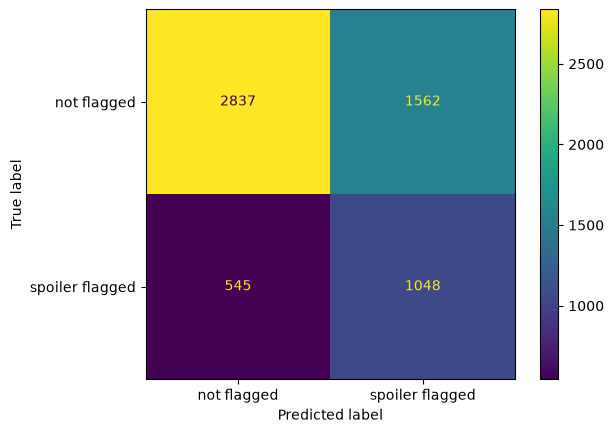

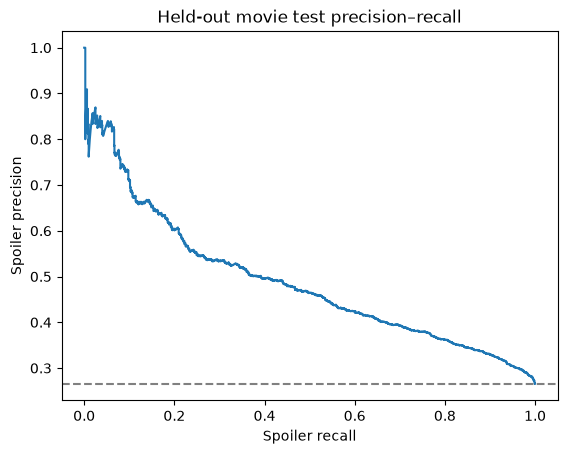

In [14]:
_,tp=predict(best_model,DataLoader(ReviewsDataset(test,length),batch_size=BATCH_SIZE))
btp=baseline.predict_proba(test.text)[:,1]
final=pd.DataFrame([
    {'model':'TF-IDF logistic',**metrics(test.label,btp,base_threshold)},
    {'model':chosen['name'],**metrics(test.label,tp,threshold)}])
display(final); final.to_csv(OUT/'final_test_metrics.csv',index=False)
print(classification_report(test.label,tp>=threshold,target_names=['not flagged','spoiler flagged'],zero_division=0))
ConfusionMatrixDisplay.from_predictions(test.label,tp>=threshold,display_labels=['not flagged','spoiler flagged'])
plt.show()
pr,rc,_=precision_recall_curve(test.label,tp)
plt.plot(rc,pr); plt.axhline(test.label.mean(),linestyle='--',color='gray')
plt.xlabel('Spoiler recall'); plt.ylabel('Spoiler precision'); plt.title('Held-out movie test precision–recall'); plt.show()
test_predictions=test.copy(); test_predictions['score']=tp; test_predictions['prediction']=(tp>=threshold).astype(int)
# Avoid exporting user IDs and full review text unnecessarily.
test_predictions[['text_hash','movie_id','label','score','prediction','n_words']].to_csv(OUT/'test_predictions.csv',index=False)


## 7A. Post-test manual audit of label disagreements
Run only after freezing the model, threshold and final test evaluation. This is a descriptive audit, not a tuning step. The target sample is up to 20 test reviews with original label 0 and model prediction 1. Six randomly selected other test reviews are mixed in to reduce expectation bias. The reader sheet hides original labels, predictions, scores and target/control membership. This is partial blinding: knowing the study design can still influence judgments. Prefer a reviewer who has not inspected the key.

**Procedure / 操作方式:** Run the export cell, open `spoiler_outputs/manual_audit_reader.csv`, and fill `human_judgment` with exactly `spoiler`, `not_spoiler`, or `uncertain`. Add a brief reason in `rationale`, and optionally a checked source in `verification_source`. Save as UTF-8 CSV and rerun the import cell below; no retraining is needed. Do not open `manual_audit_key.csv` until judgments are complete. Full original review text is shown, although the model only saw its configured prefix; `model_input_covers_review` in the key supports interpreting that limitation.

**Judgment rule / 统一标准:** Use `spoiler` for a consequential plot revelation, such as a major twist, identity of a culprit, or an important character's fate. Generic approval/disapproval and vague comments about an ending do not alone establish a spoiler. Use `uncertain` when context or plot knowledge is insufficient. Do not infer truth from the model or original flag; record any external verification used. These criteria are an operational definition for this small audit.

The export preserves existing sheets and refuses to overwrite them with a different sample/model configuration. To deliberately start a new audit, move both old files to an archive first. Never use test-audit findings to adjust this model.


In [15]:
AUDIT_TARGET_N = 20
AUDIT_CONTROL_N = 6
reader_path = OUT/'manual_audit_reader.csv'
key_path = OUT/'manual_audit_key.csv'

def make_manual_audit(predictions, target_n=20, control_n=6, seed=42):
    target_pool = predictions[(predictions.label == 0) & (predictions.prediction == 1)]
    targets = target_pool.sample(min(target_n, len(target_pool)), random_state=seed).copy()
    targets['audit_group'] = 'target_disagreement'
    controls_pool = predictions[~((predictions.label == 0) & (predictions.prediction == 1))]
    controls = controls_pool.sample(min(control_n, len(controls_pool)), random_state=seed+1).copy()
    controls['audit_group'] = 'control'
    sampled = pd.concat([targets, controls], ignore_index=True).sample(frac=1, random_state=seed+2).reset_index(drop=True)
    sampled['case_id'] = [f'CASE_{i+1:03d}' for i in range(len(sampled))]
    reader = sampled[['case_id', 'text']].copy()
    for col in ['human_judgment', 'rationale', 'verification_source']: reader[col] = ''
    key = sampled[['case_id', 'text_hash', 'movie_id', 'label', 'prediction', 'score', 'audit_group']].copy()
    key['model_name'] = chosen['name']
    key['threshold'] = threshold
    key['input_limit'] = length
    key['model_input_covers_review'] = sampled.text.map(lambda s: len(tokenize(s)) <= length)
    return reader, key, len(target_pool)

reader, audit_key, available = make_manual_audit(test_predictions, AUDIT_TARGET_N, AUDIT_CONTROL_N, SEED)
if reader_path.exists() or key_path.exists():
    if not (reader_path.exists() and key_path.exists()):
        raise RuntimeError('One audit file is missing. Restore the pair or archive the remaining file before re-exporting.')
    previous = pd.read_csv(key_path, dtype={'case_id':str, 'text_hash':str})
    # Compare sample identities and settings; preserve all manual work on reruns.
    cols = ['case_id', 'text_hash', 'audit_group', 'model_name', 'threshold', 'input_limit']
    if previous[cols].to_json(orient='records', double_precision=10) != audit_key[cols].to_json(orient='records', double_precision=10):
        raise RuntimeError('Existing audit belongs to another sample/model. Archive both audit files before creating a new pair.')
    print('Existing audit preserved. Continue editing the reader CSV; the key was not overwritten.')
else:
    reader.to_csv(reader_path, index=False, encoding='utf-8-sig')
    audit_key.to_csv(key_path, index=False, encoding='utf-8-sig')
    print(f'Exported {min(AUDIT_TARGET_N,available)} target cases and {len(reader)-min(AUDIT_TARGET_N,available)} mixed controls.')
print('Reader sheet:', reader_path.resolve())
print('Do not inspect the key or display source labels/scores until the audit is complete.')


Exported 20 target cases and 6 mixed controls.
Reader sheet: /Users/serein/Fall 2026/MGSC 673/Individual Project/spoiler_outputs/manual_audit_reader.csv
Do not inspect the key or display source labels/scores until the audit is complete.


### Import completed judgments
Blank or unfinished sheets are skipped so a first Run All can finish. Once every row is filled, rerun the cell below. It validates IDs, review text, allowed judgments and rationales. Results refer only to the selected model–label disagreement stratum; they do not estimate overall accuracy, recall for missed spoilers, or dataset-wide label error. Controls are excluded from the target summary. Your judgment is an audit assessment, not automatically a replacement ground truth.


In [16]:
def summarize_manual_audit(reader_file, key_file):
    filled = pd.read_csv(reader_file, keep_default_na=False, dtype=str)
    key = pd.read_csv(key_file, dtype={'case_id':str, 'text_hash':str})
    required = {'case_id','text','human_judgment','rationale','verification_source'}
    if not required.issubset(filled.columns):
        raise ValueError(f'Missing columns: {required-set(filled.columns)}')
    if filled.case_id.duplicated().any() or set(filled.case_id) != set(key.case_id):
        raise ValueError('Case IDs changed, duplicated or missing. Preserve the original reader rows.')
    # Verify text identity without revealing hidden labels to the reader.
    expected = key.set_index('case_id').text_hash
    actual = filled.set_index('case_id').text.map(lambda s: hashlib.sha256(s.encode()).hexdigest())
    if not actual.eq(expected.reindex(actual.index)).all():
        raise ValueError('Review text changed. Restore the original text before summarizing.')
    filled['human_judgment'] = filled.human_judgment.str.strip().str.lower()
    allowed = {'spoiler','not_spoiler','uncertain'}
    invalid = set(filled.human_judgment) - allowed - {''}
    if invalid: raise ValueError(f'Invalid judgments: {invalid}. Use spoiler/not_spoiler/uncertain.')
    incomplete = filled.human_judgment.eq('') | filled.rationale.str.strip().eq('')
    if incomplete.any():
        print(f'Audit incomplete: {int(incomplete.sum())}/{len(filled)} rows still need a judgment or rationale. No findings generated.')
        return None, None
    merged = filled.merge(key, on='case_id', validate='one_to_one')
    target = merged[merged.audit_group.eq('target_disagreement')].copy()
    counts = target.human_judgment.value_counts().reindex(['spoiler','not_spoiler','uncertain'], fill_value=0)
    summary = counts.rename_axis('human_judgment').reset_index(name='n')
    summary['fraction_of_audited_disagreements'] = summary.n/len(target) if len(target) else np.nan
    display(summary)
    print('Target cases audited:', len(target), '| Controls excluded:', int(merged.audit_group.eq('control').sum()))
    print('Possible missed user flags:', int(counts['spoiler']), '; apparent model false alarms:', int(counts['not_spoiler']), '; unresolved:', int(counts['uncertain']))
    print('These are manual assessments within sampled disagreements, not overall model performance.')
    summary.to_csv(OUT/'manual_audit_summary.csv', index=False)
    merged.to_csv(OUT/'manual_audit_completed.csv', index=False, encoding='utf-8-sig')
    return summary, merged

manual_audit_summary, completed_manual_audit = summarize_manual_audit(reader_path, key_path)


Audit incomplete: 26/26 rows still need a judgment or rationale. No findings generated.


**Write after completing / 核查后填写:** State how many target cases were available and randomly audited, who reviewed them, and the operational spoiler definition. Report all three outcomes, including uncertain cases. Discuss two or three examples with concise quotations and note whether truncated input or external plot verification mattered. A single reviewer and partial blinding limit reliability. Do not extrapolate this fraction to all unlabeled or non-spoiler-marked comments. Do not revise final test metrics using these judgments.


## 8. Post-training use: genre audit and warning demonstration
Movie metadata is optional. Join only genre; do not feed plot synopsis or IDs into the model. Movies can have several genres, so groups overlap and counts must accompany metrics. Results on small groups are descriptive, not proof of generalization differences. Do not change the model based on this test analysis.


In [17]:
details_path=DATA_DIR/'IMDB_movie_details.json'
if details_path.exists():
    movies=pd.DataFrame([{'movie_id':str(r['movie_id']),'genre':r.get('genre',[])}
                         for r in records(details_path) if r.get('movie_id')])
    assert not movies.movie_id.duplicated().any(), 'Inspect duplicate metadata IDs before joining.'
    def genre_list(g):
        if isinstance(g,list): return g or ['unknown']
        if pd.isna(g): return ['unknown']
        return [s.strip() for s in re.split(r'[,|]',str(g)) if s.strip()] or ['unknown']
    movies['genre']=movies.genre.map(genre_list)
    joined=test_predictions.merge(movies,on='movie_id',how='left',validate='many_to_one')
    joined['genre']=joined.genre.map(lambda g:g if isinstance(g,list) else ['unknown'])
    by_genre=[]
    for genre,g in joined.explode('genre').groupby('genre'):
        if len(g)>=100 and g.label.nunique()==2:
            by_genre.append({'genre':genre,'n_reviews':len(g),'n_movies':g.movie_id.nunique(),
                'spoiler_rate':g.label.mean(),**metrics(g.label,g.score,threshold)})
    genre_results=pd.DataFrame(by_genre)
    display(genre_results)
    genre_results.to_csv(OUT/'test_genre_analysis.csv',index=False)
else:
    print('Metadata absent: skip genre analysis. The warning demo below still runs.')

@torch.no_grad()
def spoiler_warning(text):
    frame=pd.DataFrame({'text':[normalize(text)],'label':[0]})
    _,p=predict(best_model,DataLoader(ReviewsDataset(frame,length),batch_size=1))
    return {'spoiler_score':round(float(p[0]),4),'threshold':round(threshold,4),
            'suggested_action':'hide behind spoiler warning' if p[0]>=threshold else 'no automatic warning',
            'tokens_seen':min(len(tokenize(normalize(text))),length)}

# Synthetic illustrative inputs; these are not labeled evaluation data.
examples=[
    'The acting was excellent, but the pacing felt slow.',
    'In the final scene, the detective discovers that his partner was the murderer.',
    'The ending surprised me. I recommend watching without reading the plot.'
]
for text in examples:
    print(text); print(spoiler_warning(text)); print()


,genre,n_reviews,n_movies,spoiler_rate,accuracy,precision,recall,f1,macro_f1,average_precision
0,Action,1984,89,0.274194,0.643649,0.411123,0.693015,0.516085,0.617037,0.520246
1,Adventure,2245,101,0.273942,0.652561,0.418073,0.684553,0.519112,0.623573,0.516480
2,Animation,272,19,0.268382,0.658088,0.409091,0.616438,0.491803,0.617093,0.441093
3,Biography,356,19,0.272472,0.620787,0.385542,0.659794,0.486692,0.593012,0.437670
4,Comedy,1273,95,0.224666,0.651218,0.336100,0.566434,0.421875,0.586078,0.378168
5,Crime,1330,67,0.249624,0.653383,0.389365,0.683735,0.496175,0.615996,0.477412
6,Drama,2901,154,0.262323,0.638056,0.385951,0.642576,0.482249,0.602015,0.477804
7,Family,456,28,0.298246,0.675439,0.470297,0.698529,0.562130,0.652145,0.534084
8,Fantasy,945,37,0.268783,0.652910,0.417040,0.732283,0.531429,0.627899,0.507858
9,History,316,10,0.294304,0.639241,0.421053,0.602151,0.495575,0.607394,0.529810


The acting was excellent, but the pacing felt slow.
{'spoiler_score': 0.0853, 'threshold': 0.4528, 'suggested_action': 'no automatic warning', 'tokens_seen': 11}

In the final scene, the detective discovers that his partner was the murderer.
{'spoiler_score': 0.5964, 'threshold': 0.4528, 'suggested_action': 'hide behind spoiler warning', 'tokens_seen': 15}

The ending surprised me. I recommend watching without reading the plot.
{'spoiler_score': 0.1682, 'threshold': 0.4528, 'suggested_action': 'no automatic warning', 'tokens_seen': 13}



**Application discussion:** Explain the demo's outputs, including any failures. A sigmoid score is not a calibrated probability. A low score does not certify spoiler-free text; only the first configured number of tokens is processed. A review-level model does not locate the spoiler sentence. Add a few genuinely new reviews if permitted, and distinguish informal demonstration from labeled evaluation.

## 9. Save reproducibility information
Model checkpoints, vocabulary, split manifests, metrics, curves and audit CSVs are generated in `spoiler_outputs/`. Source data must be acquired separately under its applicable terms. Do not redistribute the full dataset automatically.


In [18]:
config={'seed':SEED,'max_reviews':MAX_REVIEWS,'vocab_size':len(vocab),'lengths':LENGTHS,
    'epochs':EPOCHS,'patience':PATIENCE,'batch_size':BATCH_SIZE,'learning_rate':LR,
    'chosen':chosen,'baseline_threshold':base_threshold,'device':str(DEVICE),
    'split':'movie-disjoint development/test 80/20; train/validation within development 80/20',
    'versions':{name:__import__(name).__version__ for name in ['torch','numpy','pandas','sklearn','ijson']}}
(OUT/'run_config.json').write_text(json.dumps(config,indent=2,default=str),encoding='utf-8')
print('Outputs:',OUT.resolve())


Outputs: /Users/serein/Fall 2026/MGSC 673/Individual Project/spoiler_outputs


## 10. Report writing prompts / 运行后独立完成
Explain the problem, intended use, sampling and movie-disjoint evaluation. Describe the architecture and justify training settings. Compare controlled experiments, document an evidence-based iteration, and interpret precision/recall tradeoffs. Discuss validation error cases, genre results and the warning demonstration.

Discuss user-generated label uncertainty, subjectivity of spoiler definitions, long-text truncation, unseen-movie generalization, possible user overlap, English/platform representation, and erroneous hiding or exposure of content. A small manual audit cannot estimate dataset-wide label quality. Single-seed differences need cautious interpretation; if making uncertainty claims, repeat training and consider movie-cluster bootstrap rather than assuming reviews are independent.

Do not claim the model understands movie plots, proves labels wrong, or is production-ready. Replace these prompts with your own findings after execution. This notebook is an unexecuted implementation framework, not a completed empirical report.

Reference: Rishabh Misra, *IMDB Spoiler Dataset*, https://arxiv.org/abs/2212.06034 . Cite the downloaded dataset version and acquisition date. Retain any AI-assistance disclosure required by the course.
